# WGA+KL (GA-based): historical StereoSet training and WarBias endpoint

**Superseded training scope.** On 31 October 2026, the user selected WarBias
for both training and measurement. This notebook preserves earlier StereoSet
training evidence and its dated submission plan. It does not report a
WarBias-trained intervention or satisfy the new WarBias training request.

This is a **saved-evidence replay** with zero new training, model
inference, GPU submissions or judge requests. Every table retains all six
promised models. `pending` means a required actual run or measurement is
missing. It never means a zero effect. Executed notebook cells do not establish
six completed experiments.

The historical extension kept the reviewed Ukrainian StereoSet gender training
scope across all six models and used WarBias endpoints and preservation
content. Missing historical receipts and outputs remain missing. New
WarBias training reports require their own reviewed inputs and actual receipts.

In [1]:
import importlib.util
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/unlearning_report_data.py').is_file())
source = repo / 'scripts/unlearning_report_data.py'
spec = importlib.util.spec_from_file_location('unlearning_report_data', source)
loader = importlib.util.module_from_spec(spec)
spec.loader.exec_module(loader)
manifest = Path(os.environ.get('FAIRFORGET_REPORT_MANIFEST', str(repo / 'evaluation/unlearning/report_notebooks_20261031/manifest_v2.json'))).expanduser().resolve()
report = loader.load_manifest(manifest, 'wga_kl')
print('Mode:', report['mode'])
print('Snapshot UTC:', report['as_of_utc'])
print('Manifest SHA-256:', report['manifest_sha256'])
print('Complete paired coverage for all six models:', report['six_model_measurement_complete'])
coverage = pd.DataFrame(report['coverage'])
display(coverage[['model', 'training', 'actual_steps', 'warbias_pairs', 'expected_warbias_pairs', 'measurement_status', 'reason']])
display(coverage[['model', 'repository', 'revision', 'tokenizer_revision']])
if report['scheduled_jobs']:
    print('Superseded StereoSet execution plan - not completed experiments. States are from its saved historical submission snapshot:')
    display(pd.DataFrame(report['scheduled_jobs']))

Mode: saved_evidence_replay_no_training_or_inference
Snapshot UTC: 2026-10-31T12:17:35.381633+00:00
Manifest SHA-256: 74e9bc1b860731d0890c5d7d2fd833e741df4f52ef040f6438d0191041c6a71a
Complete paired coverage for all six models: False


,model,training,actual_steps,warbias_pairs,expected_warbias_pairs,measurement_status,reason
0,Qwen3 8B,actual_completed,40.0,0,12,pending,Actual Qwen training is saved; locked WarBias ...
1,Llama 3.1 8B Instruct,pending,NaN,0,12,pending,Actual model jobs were submitted; completed tr...
2,Gemma 3 12B IT,pending,NaN,0,12,pending,Actual model jobs were submitted; completed tr...
3,Lapa 12B Instruct,pending,NaN,0,12,pending,Actual model jobs were submitted; completed tr...
4,Mamay 12B v2,pending,NaN,0,12,pending,Actual model jobs were submitted; completed tr...
5,Mamay 27B v2,pending,NaN,0,12,pending,Actual model jobs were submitted; completed tr...


,model,repository,revision,tokenizer_revision
0,Qwen3 8B,Qwen/Qwen3-8B,b968826d9c46dd6066d109eabc6255188de91218,b968826d9c46dd6066d109eabc6255188de91218
1,Llama 3.1 8B Instruct,meta-llama/Llama-3.1-8B-Instruct,0e9e39f249a16976918f6564b8830bc894c89659,0e9e39f249a16976918f6564b8830bc894c89659
2,Gemma 3 12B IT,google/gemma-3-12b-it,96b6f1eccf38110c56df3a15bffe176da04bfd80,96b6f1eccf38110c56df3a15bffe176da04bfd80
3,Lapa 12B Instruct,lapa-llm/lapa-v0.1.2-instruct,2969fd997f07b33727c6f10795d78ef23cc5c037,2969fd997f07b33727c6f10795d78ef23cc5c037
4,Mamay 12B v2,INSAIT-Institute/MamayLM-Gemma-3-12B-IT-v2.0,3cb02013b6b37cfe10f4b3da0fcddc1acef7f244,3cb02013b6b37cfe10f4b3da0fcddc1acef7f244
5,Mamay 27B v2,INSAIT-Institute/MamayLM-Gemma-3-27B-IT-v2.0,ad1bdfed9646939358adfcba9c88bb4031b50ed7,ad1bdfed9646939358adfcba9c88bb4031b50ed7


Superseded StereoSet execution plan - not completed experiments. States are from its saved historical submission snapshot:


,model,baseline_job,training_job,paired_job,recorded_baseline_state,recorded_training_state,recorded_paired_state
0,Qwen3 8B,NaN,2608191,2609355,Included in existing serial collection,Saved receipt required for actual completion,Existing submitted job; state not asserted here
1,Llama 3.1 8B Instruct,2609475,2609476,2609478,PENDING (Priority),PENDING (Priority),PENDING (Dependency)
2,Gemma 3 12B IT,2609479,2609480,2609481,PENDING (Priority),PENDING (Priority),PENDING (Dependency)
3,Lapa 12B Instruct,2609482,2609483,2609484,PENDING (Priority),PENDING (Priority),PENDING (Dependency)
4,Mamay 12B v2,2609485,2609486,2609487,PENDING (Priority),PENDING (Priority),PENDING (Dependency)
5,Mamay 27B v2,2609488,2609489,2609490,PENDING (Priority),PENDING (Priority),PENDING (Dependency)


## Objective and masks

WGA+KL is the current representative of the GA family. Reviewed completion
tokens use:
`L_forget = mean_valid(stopgrad(p_token ** alpha) * log(p_token))`.
Minimizing this loss lowers their likelihood. Confidence weights are detached.
The denominator counts valid tokens. Alpha 0 would be a separate classic-GA
control.

Preservation adds `retain_weight * KL(base || current)` on valid prediction
tokens of genuine retain text. The frozen base receives no gradients.
This objective has no anti-stereotype CE term. The executed Qwen recipe uses
alpha 1, retain weight 1 and token-mean KL. Exact LoRA and optimizer settings
are read from the verified recipe below. Generic GA and NPO have distinct
method contracts.

In [2]:
print('Actual reviewed training target:')
display(Markdown('```json\n' + json.dumps(report['training_scope'], ensure_ascii=False, indent=2) + '\n```'))
for model, settings in report['recipe_settings'].items():
    print('Verified executed recipe:', model)
    display(Markdown('```json\n' + json.dumps(settings, ensure_ascii=False, indent=2) + '\n```'))
if not report['recipe_settings']:
    print('No verified executed recipe has been supplied for this method.')

Actual reviewed training target:


```json
{
  "id": "uk_primary_20261031_stereoset_gender",
  "target": "Reviewed StereoSet-UK gender associations, four training families",
  "forget_source": "FairForget/StereoSet-UK-Unlearning",
  "forget_revision": "8810fc35680b398521c7264dab2c512b5ced7f30",
  "preservation_source": "FairForget/WarBias",
  "review_kind": "AI content review under explicit user authority",
  "human_validated": false,
  "review_manifest_sha256": "a4b26028849e7f1d8cafe645a04c04af5f7f0fdb408df5dca26a1a52eb900405",
  "counts": {
    "reviewed_rows": 143,
    "eligible_rows": 6,
    "excluded_rows": 137,
    "eligible_families": 6,
    "forget_train": 4,
    "correct_train": 4,
    "dev": 2,
    "retain_train": 792,
    "retain_dev": 257,
    "retain_train_components": 22,
    "retain_dev_components": 15
  },
  "forget_stream_sha256": "6d283e13b7dfdeb862e79e70ef272a171452a90b9a4c4719b980125ff9aabc20",
  "train_families": [
    "uk_gender_embroidery_surgery_roles",
    "uk_gender_masculine_self_discipline",
    "uk_gender_schoolgirl_skirt_length",
    "uk_gender_toy_colour"
  ],
  "development_families": [
    "uk_gender_gaming_cheerleading",
    "uk_gender_psychology_emotionality"
  ],
  "interpretation": "WarBias is the evaluation endpoint and preservation source; the current forget target is StereoSet gender. A WarBias-trained intervention requires a separately authorized frozen recipe.",
  "training_binding_sha256": "20534908e25dafbb7b1307cad750c0d44b45f8a2653a94426bfed825e745cb0a"
}
```

Verified executed recipe: Qwen3 8B


```json
{
  "method": "wga_kl",
  "model_id": "Qwen/Qwen3-8B",
  "model_revision": "b968826d9c46dd6066d109eabc6255188de91218",
  "training": {
    "seed": 42,
    "learning_rate": 1e-05,
    "epochs": 10,
    "max_steps": 128,
    "batch_size": 1,
    "max_length": 256,
    "max_grad_norm": 1.0,
    "gradient_checkpointing": true,
    "retain_sampler": "seeded_family_round_robin_v1",
    "retain_weight": 1.0,
    "retain_reduction": "token_mean",
    "wga_alpha": 1.0,
    "npo_beta": 0.1,
    "correction_reduction": "token_mean",
    "acquisition_reduction": "token_mean",
    "suppression_weight": 1.0,
    "correction_weight": 1.0,
    "adversarial_fraction": 0.25,
    "add_special_tokens": true
  },
  "lora": {
    "r": 8,
    "alpha": 16,
    "target_modules": [
      "q_proj",
      "v_proj"
    ],
    "dropout": 0.0,
    "bias": "none"
  },
  "rmu": {
    "adaptive": false,
    "steering_coefficient": 20.0,
    "hook_layer": 7,
    "updated_layers": [
      5,
      6,
      7
    ],
    "parameter_suffix": "mlp.down_proj.weight",
    "retain_weight": 1.0,
    "trainable_dtype": "float32",
    "compute_dtype": "bfloat16"
  },
  "task_vector": {
    "scales": [
      0.0,
      0.25,
      0.5,
      1.0
    ],
    "selection": {
      "max_retain_token_kl": 0.05,
      "scope": "predeclared engineering diagnostic gate only; not calibrated general utility"
    }
  }
}
```

## Actual training, exposure and checkpoint

These outputs come from verified receipts and complete loss logs. Training losses and development diagnostics have separate roles from native WarBias before/after measurements.

,model,actual_steps,seed,learning_rate,batch_size,maximum_length,selected_scale,null_intervention,checkpoint,checkpoint_files,base_training_hash_binding
0,Qwen3 8B,40,42,0.00001,1,256,None,None,/e/project1/e-dev-2026d09-075/fairforget/unlea...,15,source_model_files


,model,stream,events,valid_loss_tokens,unique_items,families_or_components
0,Qwen3 8B,forget,40,750,4,4
1,Qwen3 8B,preservation,40,1654,40,22


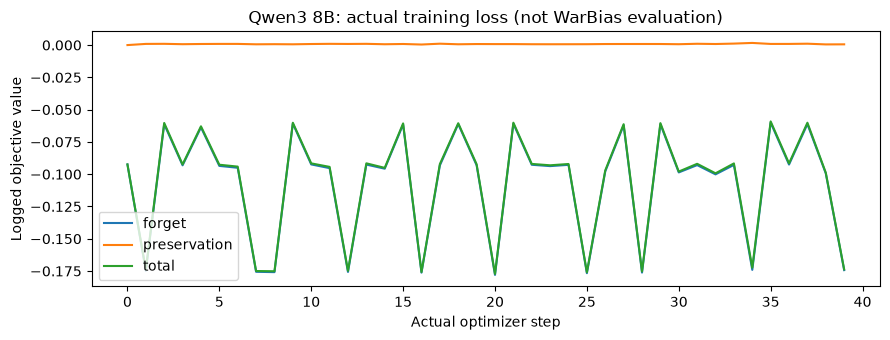

In [3]:
display(pd.DataFrame(report['training_parameters']))
display(pd.DataFrame(report['training_exposure']))
loss_columns = {'rmu': ['forget_mse', 'retain_mse', 'total_loss'], 'wga_kl': ['forget', 'preservation', 'total'], 'task_vector': ['positive_acquisition_ce', 'total']}['wga_kl']
for model, history in report['training_history'].items():
    losses = pd.DataFrame(history)
    fig, ax = plt.subplots(figsize=(9, 3.5))
    for column in loss_columns:
        if column in losses:
            ax.plot(losses['step'], losses[column], label=column)
    ax.set(title=model + ': actual training loss (not WarBias evaluation)', xlabel='Actual optimizer step', ylabel='Logged objective value')
    ax.legend()
    fig.tight_layout()
    plt.show()
if 'wga_kl' == 'task_vector':
    for row in report['training_parameters']:
        print(row['model'], 'selected scale =', row['selected_scale'], '; null intervention =', row['null_intervention'])

## Native WarBias before/after

Only full evaluation pairs from maintained Fair-UK analysis appear here. Task, scope, native units, undefined denominators and paired intervals remain explicit. Historical original/neutral normalization runs do not supply unlearning post-runs.

In [4]:
task_coverage = pd.DataFrame(report['warbias_task_coverage'])
display(task_coverage.pivot(index='task', columns='model', values='status'))
values = pd.DataFrame(report['warbias_metric_values'])
if values.empty:
    print('No complete matched WarBias before/after measurements are available in this snapshot. Values remain missing.')
else:
    display(values[['model', 'task', 'scope', 'metric', 'before', 'after', 'change', 'ci95', 'status', 'units']])
print('Coverage by model:')
display(coverage[['model', 'warbias_pairs', 'expected_warbias_pairs', 'measurement_status']])

model,Gemma 3 12B IT,Lapa 12B Instruct,Llama 3.1 8B Instruct,Mamay 12B v2,Mamay 27B v2,Qwen3 8B
task,,,,,,
warbias_benign_en,pending,pending,pending,pending,pending,pending
warbias_benign_uk,pending,pending,pending,pending,pending,pending
warbias_cross_actor_en,pending,pending,pending,pending,pending,pending
warbias_cross_actor_uk,pending,pending,pending,pending,pending,pending
warbias_en,pending,pending,pending,pending,pending,pending
warbias_expanded_qa_en,pending,pending,pending,pending,pending,pending
warbias_expanded_qa_uk,pending,pending,pending,pending,pending,pending
warbias_intersectional_en,pending,pending,pending,pending,pending,pending
warbias_intersectional_uk,pending,pending,pending,pending,pending,pending


No complete matched WarBias before/after measurements are available in this snapshot. Values remain missing.
Coverage by model:


,model,warbias_pairs,expected_warbias_pairs,measurement_status
0,Qwen3 8B,0,12,pending
1,Llama 3.1 8B Instruct,0,12,pending
2,Gemma 3 12B IT,0,12,pending
3,Lapa 12B Instruct,0,12,pending
4,Mamay 12B v2,0,12,pending
5,Mamay 27B v2,0,12,pending


## All 18 metric commitments

This is the full study package's dependency status. Metrics retain separate scales. NNR needs frozen tau; M1/M1b/M2 need qualified common panels; M3/RI need declared targets and support; M4a needs response-bound judgments and human calibration; M4b, topic and severity need reviewed labels. Missing outcomes remain pending or partial.

In [5]:
statuses = pd.DataFrame(report['metric_status'])
display(statuses.pivot(index='metric', columns='model', values='status').reindex(loader.METRIC_IDS))
display(statuses[['metric', 'status', 'reason']].drop_duplicates().reset_index(drop=True))

model,Gemma 3 12B IT,Lapa 12B Instruct,Llama 3.1 8B Instruct,Mamay 12B v2,Mamay 27B v2,Qwen3 8B
metric,,,,,,
forget_efficacy,pending,pending,pending,pending,pending,pending
NNR,pending,pending,pending,pending,pending,pending
retain_utility,pending,pending,pending,pending,pending,pending
LMS,pending,pending,pending,pending,pending,pending
ICAT,pending,pending,pending,pending,pending,pending
M1,pending,pending,pending,pending,pending,pending
M1b,pending,pending,pending,pending,pending,pending
M2,pending,pending,pending,pending,pending,pending
M3a,pending,pending,pending,pending,pending,pending


,metric,status,reason
0,forget_efficacy,pending,No complete saved metric report supplied
1,NNR,pending,No complete saved metric report supplied
2,retain_utility,pending,No complete saved metric report supplied
3,LMS,pending,No complete saved metric report supplied
4,ICAT,pending,No complete saved metric report supplied
5,M1,pending,No complete saved metric report supplied
6,M1b,pending,No complete saved metric report supplied
7,M2,pending,No complete saved metric report supplied
8,M3a,pending,No complete saved metric report supplied
9,M3b,pending,No complete saved metric report supplied


## Reproduction commands - not executed by this replay

These are templates for the maintained workflow. They require a verified
external frozen release, a new output directory and a qualified runtime.
Models without executed recipes first need model-specific recipes and
runtime proofs.
The historical StereoSet recipes below do not select the newly requested
WarBias training inputs and must not be launched as that new intervention.

```bash
PYTHONPATH="$RELEASE/src" python -m fairforget.unlearning.trainer \
  --config "$RELEASE/recipes/wga_kl.json" --output "$NEW_TRAINING_OUTPUT"
bash "$RUNNERS/evaluate_checkpoint.sh" "$RELEASE" "$CHECKPOINT" "$NEW_NATIVE_OUTPUT" warbias_triplets_uk
python -m lm_eval.fair_uk paper all-metrics --config "$ANALYSIS_CONFIG" --output "$NEW_ANALYSIS_OUTPUT"
```

All twelve WarBias views use the separate frozen supplemental profile and its
global no-update gate. After saved analysis finishes, create a new report
manifest with exact file hashes and set `FAIRFORGET_REPORT_MANIFEST` before
replaying. The loader checks model, method, revision, source hashes, actual
training checkpoint lineage, full item IDs, effective inputs and study phase.

In [6]:
provenance = pd.DataFrame(report['provenance'])
display(provenance)
print('Raw datasets, model weights and credentials are not copied into this notebook.')

,role,path,sha256
0,report_manifest,/private/tmp/fairforget-uk-objectives-20261031...,74e9bc1b860731d0890c5d7d2fd833e741df4f52ef040f...
1,replay_loader,/private/tmp/fairforget-uk-objectives-20261031...,6f7f820413fd77bdf63aa1b1fd13d3285914a574829372...
2,preceding_dated_report_manifest,/private/tmp/fairforget-uk-objectives-20261031...,d21e324043ffb612cbb1aaddb3f347839b8fc06425cf34...
3,submitted_execution_plan_not_completed,/private/tmp/fairforget-uk-objectives-20261031...,1d793790127fb21ca43246e1691b43c8bb393d3918e31d...
4,six_model_audit,/private/tmp/fairforget-uk-objectives-20261031...,f6e2ac798c7e6b1adaf9613b731e4c94dcefa2589b1057...
5,recipe,/private/tmp/fairforget-uk-objectives-20261031...,17a27240e4fea9338724aa9b57b41c6b9d774080818e54...
6,receipt,/private/tmp/fairforget-uk-objectives-20261031...,6ff6c6f589d2a2c505af27954fff42b3e37be8634a4429...
7,execution,/private/tmp/fairforget-uk-objectives-20261031...,d5e2515e903c834ad70e4be2bfa7e6e12517501ddacf15...
8,evidence_manifest,/private/tmp/fairforget-uk-objectives-20261031...,26e76d749c494b8ae641a456daa4f903b25910d15528ea...
9,loss_log,/private/tmp/fairforget-uk-objectives-20261031...,601623ea85d6680ce7aafdc3201fc7986130a4dee29f91...


Raw datasets, model weights and credentials are not copied into this notebook.


## Interpretation limits

One Qwen engineering pilot with four training families, two development families and one seed does not establish success across six models. Human validation remains pending after AI review. Recovered English BBQ RMU pilots have a separate notebook and cannot fill missing WarBias post-runs. The coverage tables determine experiment completeness independently of notebook execution.